# Práctica guiada — Inferencia y contratos

Este notebook es para el alumnado. Completa las celdas marcadas con `TODO` y responde las preguntas antes de mirar la solución docente.

**Objetivo:** pasar de una fila CSV a una especificación clara para el módulo de inferencia de la clase 2.

## Cómo trabajar

1. Copia esta carpeta como tu espacio de trabajo.
2. Ejecuta `uv sync` desde `problem/starter/` cuando empiece la clase 2.
3. En esta práctica no implementes todavía el CLI completo.
4. Trabaja en parejas y cambia quién escribe cada diez minutos.
5. No abras `solutions/` hasta el debrief.

In [1]:
from dataclasses import dataclass
import csv
from pathlib import Path

from pydantic import BaseModel, ConfigDict, Field, ValidationError

DATA_PATH = Path("../../../../../../assets/03-wine-quality/inference_samples.csv")
print(DATA_PATH)
print(DATA_PATH.exists())

../../../../../../assets/03-wine-quality/inference_samples.csv
True


## 1. Leer los datos nuevos

### Práctica A — Inspección del CSV

Completa la celda siguiente para:

- Leer el CSV con `csv.DictReader`.
- Imprimir el número de filas.
- Imprimir las columnas.
- Guardar la primera fila en una variable llamada `row`.

In [2]:
# implementa la lectura del CSV.
# Pista: usa DATA_PATH.open(newline="", encoding="utf-8")
rows = []
row = {}
with DATA_PATH.open(newline="", encoding="utf-8") as csvfile:
    reader = csv.DictReader(csvfile)
    for row in reader:
        rows.append(row)
        print(row)

{'sample_id': 'red-001', 'fixed_acidity': '7.4', 'volatile_acidity': '0.7', 'citric_acid': '0.0', 'residual_sugar': '1.9', 'chlorides': '0.076', 'free_sulfur_dioxide': '11.0', 'total_sulfur_dioxide': '34.0', 'density': '0.9978', 'ph': '3.51', 'sulphates': '0.56', 'alcohol': '9.4'}
{'sample_id': 'red-002', 'fixed_acidity': '7.8', 'volatile_acidity': '0.88', 'citric_acid': '0.0', 'residual_sugar': '2.6', 'chlorides': '0.098', 'free_sulfur_dioxide': '25.0', 'total_sulfur_dioxide': '67.0', 'density': '0.9968', 'ph': '3.2', 'sulphates': '0.68', 'alcohol': '9.8'}
{'sample_id': 'red-003', 'fixed_acidity': '11.2', 'volatile_acidity': '0.28', 'citric_acid': '0.56', 'residual_sugar': '1.9', 'chlorides': '0.075', 'free_sulfur_dioxide': '17.0', 'total_sulfur_dioxide': '60.0', 'density': '0.998', 'ph': '3.16', 'sulphates': '0.58', 'alcohol': '9.8'}
{'sample_id': 'red-004', 'fixed_acidity': '7.3', 'volatile_acidity': '0.65', 'citric_acid': '0.0', 'residual_sugar': '1.2', 'chlorides': '0.065', 'free_

### Preguntas

1. ¿Qué campo identifica la muestra pero no es una característica del modelo?
sample_id
2. ¿Cuántas características numéricas hay?
11
3. ¿Qué columna extra añadirías para probar el contrato?
No añadiría ninguna columna ya que se deben validar las que queremos usar para el modelo, en todo caso quitaría sample_id ya que no le aporta información relevante
4. ¿Qué valor de `ph` sería claramente inválido?
-1

## 2. Construir el contrato con Pydantic

El contrato del modelo contiene estas características:

| Campo | Rango orientativo | Unidades | Admite nulos |
|---|---|---|---|
| `fixed_acidity` | 0–20 | g/L | No |
| `volatile_acidity` | 0–2 | g/L | No |
| `citric_acid` | 0–2 | g/L | No |
| `residual_sugar` | 0–20 | g/L | No |
| `chlorides` | 0–1 | g/L | No |
| `free_sulfur_dioxide` | 0–100 | mg/L | No |
| `total_sulfur_dioxide` | 0–300 | mg/L | No |
| `density` | 0.98–1.01 | g/cm^3 | No |
| `ph` | 2.5–4.5 | sin unidad | No |
| `sulphates` | 0–3 | g/L | No |
| `alcohol` | 5–20 | % | No |

In [3]:
class WineQualityRequestPydantic(BaseModel):
    # prohíbe campos extra con model_config.
    # declara las 11 características con Field(ge=..., le=...).
    model_config = ConfigDict(extra="forbid")

    fixed_acidity: float = Field(ge=0, le=20)
    volatile_acidity: float = Field(ge=0, le=2)
    citric_acid: float = Field(ge=0, le=2)
    residual_sugar: float = Field(ge=0, le=20)
    chlorides: float = Field(ge=0, le=1)
    free_sulfur_dioxide: float = Field(ge=0, le=100)
    total_sulfur_dioxide: float = Field(ge=0, le=300)
    density: float = Field(ge=0.98, le=1.01)
    ph: float = Field(ge=2.5, le=4.5)
    sulphates: float = Field(ge=0, le=3)
    alcohol: float = Field(ge=5, le=20)

# separa sample_id de la fila y valida solo las características del modelo.
# model_row = ...
# request = WineQualityRequestPydantic.model_validate(model_row)
model_row = {k: float(v) for k, v in row.items() if k != "sample_id"}
request = WineQualityRequestPydantic.model_validate(model_row)

### Práctica B — Validación

Completa una prueba para cada caso:

- Una fila válida.
- Una columna `unexpected_field`.
- Un `ph` fuera de rango.

Antes de ejecutar, escribe qué error esperas.

In [4]:
# TODO: completa los casos y captura ValidationError.
# try:
#     ...
# except ValidationError as error:
#     print(error)
valid_row = {
    "fixed_acidity": 7.4,
    "volatile_acidity": 0.7,
    "citric_acid": 0.0,
    "residual_sugar": 1.9,
    "chlorides": 0.076,
    "free_sulfur_dioxide": 11.0,
    "total_sulfur_dioxide": 34.0,
    "density": 0.9978,
    "ph": 3.51,
    "sulphates": 0.56,
    "alcohol": 9.4,
}
unxpected_field_row = {
    "fixed_acidity": 7.4,
    "volatile_acidity": 0.7,
    "citric_acid": 0.0,
    "residual_sugar": 1.9,
    "chlorides": 0.076,
    "free_sulfur_dioxide": 11.0,
    "total_sulfur_dioxide": 34.0,
    "density": 0.9978,
    "ph": 3.51,
    "sulphates": 0.56,
    "alcohol": 9.4,
    "unexpected_field": 1.0,
}

ph_out_of_range_row = {
    "fixed_acidity": 7.4,
    "volatile_acidity": 0.7,
    "citric_acid": 0.0,
    "residual_sugar": 1.9,
    "chlorides": 0.076,
    "free_sulfur_dioxide": 11.0,
    "total_sulfur_dioxide": 34.0,
    "density": 0.9978,
    "ph": 5.0,
    "sulphates": 0.56,
    "alcohol": 9.4,
}

try:
    request = WineQualityRequestPydantic.model_validate(valid_row)
    print("Fila válida pasa la validación.")
except ValidationError as error: # No debería llegar aquí
    print("Fila válida falla:", error)

try:
    request = WineQualityRequestPydantic.model_validate(unxpected_field_row)
    print("Fila con campo inesperado pasa la validación.")
except ValidationError as error:
    print("Fila con campo inesperado falla:", error)

try:
    request = WineQualityRequestPydantic.model_validate(ph_out_of_range_row)
    print("Fila con pH fuera de rango pasa la validación.")
except ValidationError as error:
    print("Fila con pH fuera de rango falla:", error)

Fila válida pasa la validación.
Fila con campo inesperado falla: 1 validation error for WineQualityRequestPydantic
unexpected_field
  Extra inputs are not permitted [type=extra_forbidden, input_value=1.0, input_type=float]
    For further information visit https://errors.pydantic.dev/2.14/v/extra_forbidden
Fila con pH fuera de rango falla: 1 validation error for WineQualityRequestPydantic
ph
  Input should be less than or equal to 4.5 [type=less_than_equal, input_value=5.0, input_type=float]
    For further information visit https://errors.pydantic.dev/2.14/v/less_than_equal


## 3. Comparar con `dataclass`

Construye la misma estructura con `dataclass`. No añadas todavía validación manual: observa qué garantiza Python y qué no garantiza.

In [5]:
@dataclass(frozen=True, slots=True)
class WineQualityRequestDataclass:
    # declara las mismas 11 características.
    fixed_acidity: float
    volatile_acidity: float
    citric_acid: float
    residual_sugar: float
    chlorides: float
    free_sulfur_dioxide: float
    total_sulfur_dioxide: float
    density: float
    ph: float
    sulphates: float
    alcohol: float

# crea una instancia válida y prueba qué ocurre con ph=99.0.
valid_instance = WineQualityRequestDataclass(
    fixed_acidity=7.4,
    volatile_acidity=0.7,
    citric_acid=0.0,
    residual_sugar=1.9,
    chlorides=0.076,
    free_sulfur_dioxide=11.0,
    total_sulfur_dioxide=34.0,
    density=0.9978,
    ph=99.0,
    sulphates=0.56,
    alcohol=9.4
)

### Decisión de diseño

Completa la frase:

> Usaría Pydantic en datos que requieran validación porque tiene validación automática, manejo de errores y transformación de tipos. Usaría `dataclass` en datos sin o con poca validación porque es más rápido y permite hacer el objeto inmutable.

## 4. Definir el orden del vector

El modelo no recibe un diccionario. Recibe una lista numérica con un orden estable.

In [6]:
# rellena el orden exacto a partir del CSV y del contrato.
FEATURE_NAMES = (
    # "fixed_acidity",
    # ...
    "fixed_acidity",
    "volatile_acidity",
    "citric_acid",
    "residual_sugar",
    "chlorides",
    "free_sulfur_dioxide",
    "total_sulfur_dioxide",
    "density",
    "ph",
    "sulphates",
    "alcohol"
)

# construye vector usando getattr(request, name).
# vector = [...]
vector = [getattr(request, name) for name in FEATURE_NAMES]

### Práctica C — Error de orden

Intercambia mentalmente `density` y `alcohol`. Responde:

- ¿El vector sigue teniendo 11 valores? Sí
- ¿El clasificador detectaría necesariamente el error? No
- ¿Cómo evitarías que cada script definiera un orden distinto? Definiendo un orden de referencia junto al modelo y que todo fichero que lo use deba cumplirlo

## 5. Contrato de salida

Diseña la estructura que devolverá el módulo. Debe permitir responder:

- ¿Qué muestra se ha procesado?
- ¿Qué categoría se ha predicho?
- ¿Con qué confianza?
- ¿Qué versión de modelo y preprocesado se utilizaron?

In [7]:
class WineQualityPredictionPydantic(BaseModel):
    # declara los campos de salida y sus restricciones.
    sample_id: str
    quality_band: int = Field(ge=3, le=8)
    confidence: float = Field(ge=0.0, le=1.0)
    model_version: str = Field(min_length=1)
    preprocessing_version: str = Field(min_length=1)


# escribe un ejemplo de salida para red-001.
output_example = WineQualityPredictionPydantic(
    sample_id="red_001",
    quality_band=6,
    confidence=0.85,
    model_version="wine-quality-model-1.0",
    preprocessing_version="1.0"
)

Criterios de ejecución:

* Dada una fila válida del CSV, el vector que le llega al modelo tiene 11 valores en el orden del contrato y no incluye sample_id.

* Dada una fila con una columna desconocida o un valor fuera de rango, se debe lanzar un error claro sin llegar a predecir.

* Dada una fila válida, la salida contiene sample_id, quality_band, confidence, model_version y preprocessing_version.

## 6. Demo del docente: observar la inferencia

El docente ejecutará el notebook resuelto y el comando de referencia. Mientras tanto, anota el recorrido:

```text
CSV → contrato → preprocesado → modelo cargado → predicción
```

No copies la implementación. Tu código de producción empieza en la clase 2 con el starter.

## Entrega

Entrega una captura o exportación con:

- La tabla de contrato.
- Las respuestas de las prácticas A, B y C.
- El orden de las 11 características.
- Un ejemplo de entrada inválida.
- Un contrato de salida.
- Tu plan de implementación para `contracts.py`, `preprocess.py`, `inference.py` y `predict_file.py`.

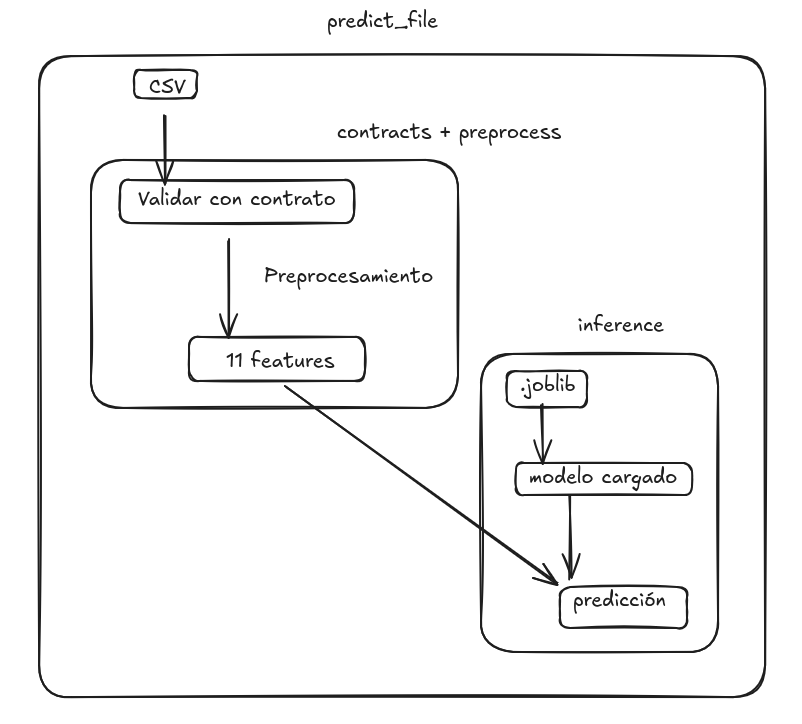